# **LIBRARIES USED**

In [1]:
import pandas as pd
import numpy aas np
import matplotlib.pyplot as plt

# Display more columns in the output
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


# **DATASET LOADING**

In [3]:
file_path = "../data/raw/Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Number of rows: 541909
Number of columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


# **DATA INSPECT BEFORE CLEANING**

In [4]:
# Check column names and data types
df.info()

# Count missing values
print("\nMissing values:")
print(df.isnull().sum())

# Count duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check basic statistics
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


# **DATA CLEANING**

In [5]:
# Keep an unchanged copy of the imported data
df_clean = df.copy()

# Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.replace(" ", "_")
)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Convert date column to datetime format
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# Remove records with missing essential transaction fields
df_clean = df_clean.dropna(
    subset=["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"]
)

# Convert invoice numbers to strings
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)

# Identify cancelled invoices (invoice numbers starting with C)
df_clean["IsCancelled"] = (
    df_clean["InvoiceNo"].str.startswith("C")
)

# Identify rows with non-positive quantity or price
df_clean["IsInvalidSale"] = (
    (df_clean["Quantity"] <= 0) |
    (df_clean["UnitPrice"] <= 0)
)

print("Original rows:", len(df))
print("Rows after basic cleaning:", len(df_clean))
print("Cancelled invoice rows:", df_clean["IsCancelled"].sum())
print("Non-positive quantity/price rows:",
      df_clean["IsInvalidSale"].sum())

Original rows: 541909
Rows after basic cleaning: 536641
Cancelled invoice rows: 9251
Non-positive quantity/price rows: 11763


# **CREATED ANALYSIS DATASET**

In [6]:
sales_df = df_clean[
    (~df_clean["IsCancelled"]) &
    (~df_clean["IsInvalidSale"])
].copy()

# Calculate revenue for each transaction line
sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

# Create date analysis columns
sales_df["Year"] = sales_df["InvoiceDate"].dt.year
sales_df["Month"] = sales_df["InvoiceDate"].dt.month
sales_df["MonthName"] = sales_df["InvoiceDate"].dt.strftime("%b")

print("Valid sales rows:", len(sales_df))
print("Total revenue:", round(sales_df["Revenue"].sum(), 2))

sales_df.head()

Valid sales rows: 524878
Total revenue: 10642110.8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,IsInvalidSale,Revenue,Year,Month,MonthName
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,False,15.30,2010,12,Dec
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,20.34,2010,12,Dec
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,False,22.00,2010,12,Dec
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,20.34,2010,12,Dec
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,20.34,2010,12,Dec


# **SAVED CLEANING**

In [7]:
from pathlib import Path

output_folder = Path("../data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

sales_df.to_csv(
    output_folder / "retail_sales_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


# **VERIFY**

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load the cleaned dataset
file_path = Path("../data/processed/retail_sales_cleaned.csv")

sales_df = pd.read_csv(file_path, parse_dates=["InvoiceDate"])

# Display basic information
print("Rows and columns:", sales_df.shape)
print("\nColumn names:")
print(sales_df.columns.tolist())

print("\nFirst 5 rows:")
display(sales_df.head())
    
print("\nMissing values:")
print(sales_df.isnull().sum())

C:\Users\DELL\AppData\Local\Temp\ipykernel_31148\434185471.py:9: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  sales_df = pd.read_csv(file_path, parse_dates=["InvoiceDate"])


Rows and columns: (524878, 14)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'IsCancelled', 'IsInvalidSale', 'Revenue', 'Year', 'Month', 'MonthName']

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,IsInvalidSale,Revenue,Year,Month,MonthName
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,False,15.30,2010,12,Dec
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,20.34,2010,12,Dec
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,False,22.00,2010,12,Dec
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,20.34,2010,12,Dec
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,20.34,2010,12,Dec



Missing values:
InvoiceNo             0
StockCode             0
Description           0
Quantity              0
InvoiceDate           0
UnitPrice             0
CustomerID       132186
Country               0
IsCancelled           0
IsInvalidSale         0
Revenue               0
Year                  0
Month                 0
MonthName             0
dtype: int64


# **EDA**

In [9]:
# 1. Total Revenue
total_revenue = sales_df["Revenue"].sum()

# 2. Total Orders
total_orders = sales_df["InvoiceNo"].nunique()

# 3. Total Quantity Sold
total_quantity = sales_df["Quantity"].sum()

# 4. Average Order Value
average_order_value = total_revenue / total_orders

# 5. Unique Customers
unique_customers = sales_df["CustomerID"].nunique()

print("===== RETAIL SALES SUMMARY =====")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")
print(f"Unique Customers: {unique_customers:,}")

===== RETAIL SALES SUMMARY =====
Total Revenue: £10,642,110.80
Total Orders: 19,962
Total Quantity Sold: 5,572,420
Average Order Value: £533.12
Unique Customers: 4,338


# **ANALYZE MONTHLY SALES**

In [10]:
# Group sales by month
monthly_sales = (
    sales_df.groupby(
        sales_df["InvoiceDate"].dt.to_period("M")
    )["Revenue"]
    .sum()
    .sort_index()
)

print(monthly_sales)

InvoiceDate
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64


# **MONTHLY SALES CHART**

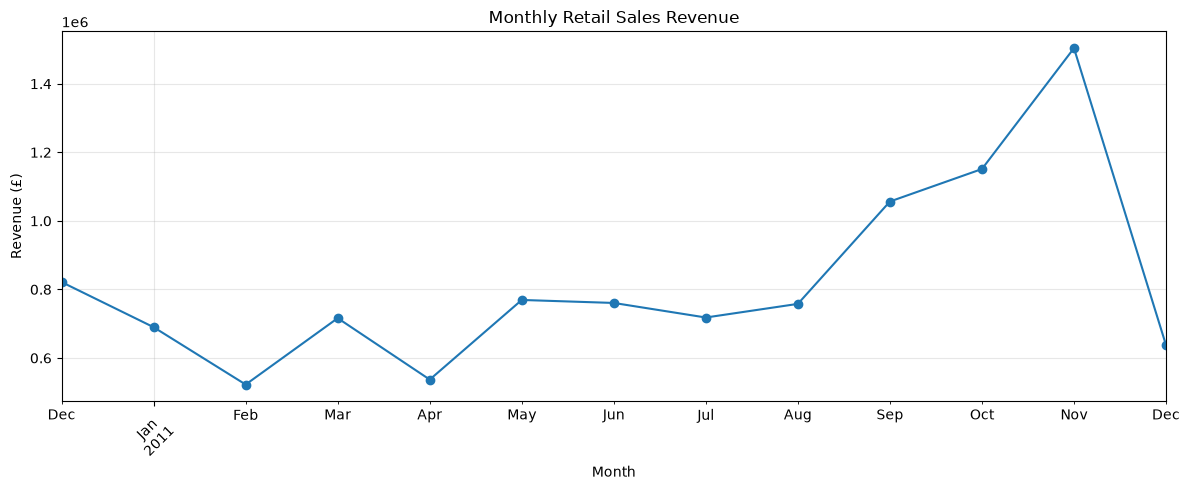

In [11]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Retail Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("../outputs/monthly_sales.png", dpi=300)
plt.show()

# **FINDING TOP 10 PRODUCTS**

In [12]:
top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


# **VISUALIZE**

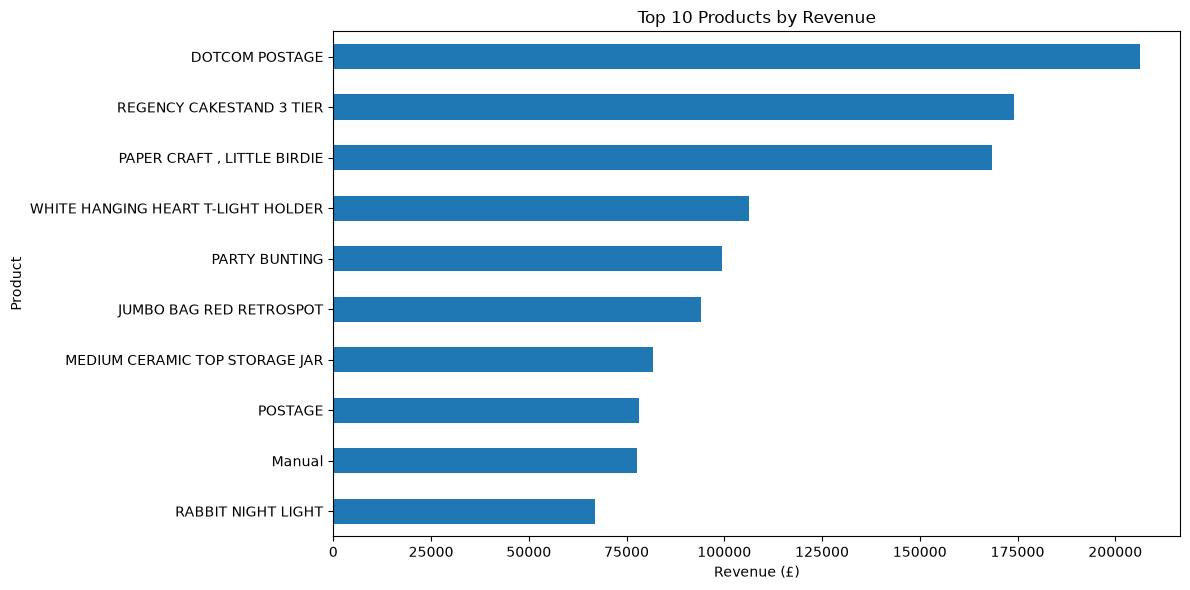

In [13]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig("../outputs/top_products.png", dpi=300)
plt.show()

# **SALES BY COUNTRY**

In [14]:
country_sales = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 countries by revenue:")
print(country_sales.head(10))

Top 10 countries by revenue:
Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


# **VISUALIZE THE RESULTS**

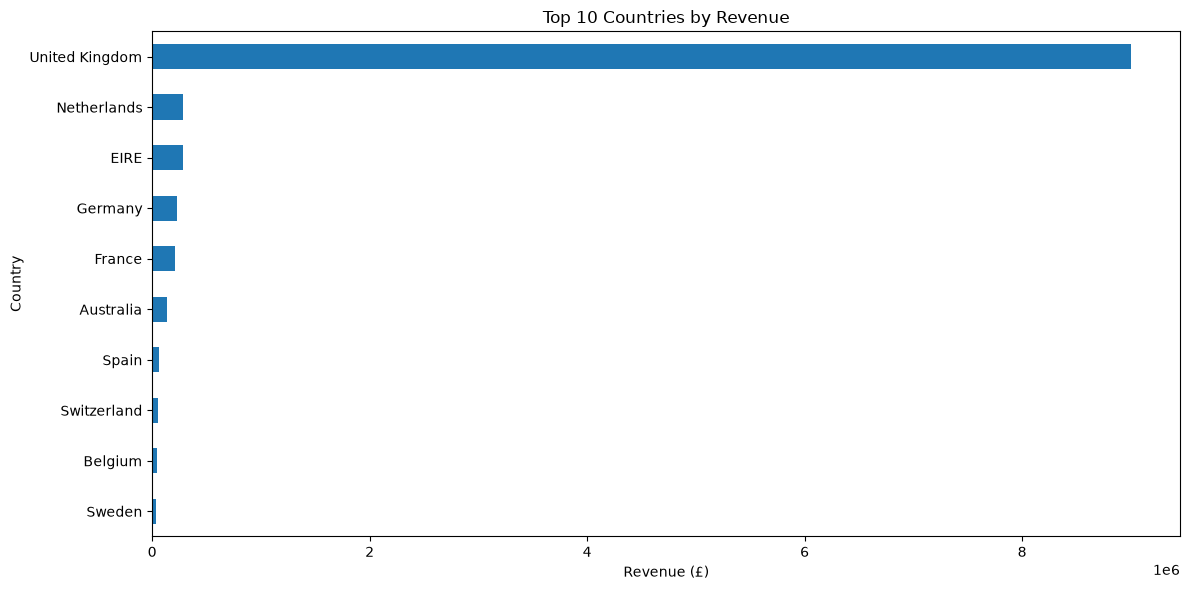

In [15]:
plt.figure(figsize=(12, 6))

country_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig("../outputs/country_sales.png", dpi=300)
plt.show()

# **ANALYZE REPEATED CUSTOMERS**

In [16]:
customer_orders = (
    sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

repeat_customers = (customer_orders > 1).sum()
one_time_customers = (customer_orders == 1).sum()

print("Repeat customers:", repeat_customers)
print("One-time customers:", one_time_customers)

Repeat customers: 2845
One-time customers: 1493


In [ ]:
#improved function code

In [17]:
def calculate_kpis(df):
    """Calculate key retail sales performance metrics."""

    revenue = df["Revenue"].sum()
    orders = df["InvoiceNo"].nunique()
    quantity = df["Quantity"].sum()

    average_order_value = (
        revenue / orders if orders > 0 else 0
    )

    return {
        "Total Revenue": round(revenue, 2),
        "Total Orders": orders,
        "Total Quantity": quantity,
        "Average Order Value": round(
            average_order_value, 2
        )
    }


kpis = calculate_kpis(sales_df)

for metric, value in kpis.items():
    print(f"{metric}: {value}")

Total Revenue: 10642110.8
Total Orders: 19962
Total Quantity: 5572420
Average Order Value: 533.12


# **VALIDATION CHECKS**

In [18]:
# Check required columns
required_columns = [
    "InvoiceNo",
    "InvoiceDate",
    "Quantity",
    "UnitPrice",
    "Revenue"
]

assert all(
    col in sales_df.columns
    for col in required_columns
), "Required columns are missing!"

# Validate revenue calculation
expected_revenue = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

assert np.allclose(
    sales_df["Revenue"],
    expected_revenue
), "Revenue calculation mismatch!"

# Check for missing essential values
assert sales_df[
    ["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"]
].notna().all().all(), "Missing essential values!"

print("All validation checks passed!")

All validation checks passed!
